In [1]:
from google.colab import files

uploaded = files.upload()

Saving spoken+arabic+digit.zip to spoken+arabic+digit (1).zip


In [2]:
import os
import zipfile

zip_name = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_name is None:
    raise ValueError("Please upload the dataset as a ZIP file.")

DATA_DIR = "/content/spoken+arabic+digit"
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

for root, dirs, filenames in os.walk(DATA_DIR):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/spoken+arabic+digit/spoken+arabic+digit/Train_Arabic_Digit.txt
/content/spoken+arabic+digit/spoken+arabic+digit/documentation.html
/content/spoken+arabic+digit/spoken+arabic+digit/Test_Arabic_Digit.txt
/content/spoken+arabic+digit/spoken+arabic+digit/graphic.jpg


In [3]:
TRAIN_FILE = None
TEST_FILE = None

for root, dirs, filenames in os.walk(DATA_DIR):
    for filename in filenames:
        if filename.lower() == "train_arabic_digit.txt":
            TRAIN_FILE = os.path.join(root, filename)
        elif filename.lower() == "test_arabic_digit.txt":
            TEST_FILE = os.path.join(root, filename)

print("Training file:", TRAIN_FILE)
print("Testing file:", TEST_FILE)

assert TRAIN_FILE is not None, "Training file not found"
assert TEST_FILE is not None, "Testing file not found"

Training file: /content/spoken+arabic+digit/spoken+arabic+digit/Train_Arabic_Digit.txt
Testing file: /content/spoken+arabic+digit/spoken+arabic+digit/Test_Arabic_Digit.txt


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [6]:
import re
def load_sequences(file_path):
    with open(file_path, "r") as file:
        content = file.read().strip()

    blocks = re.split(r'\n[ \t]*\n', content)
    sequences = []

    for block in blocks:
        rows = [
            line.split()
            for line in block.splitlines()
            if line.strip()
        ]

        if rows:
            sequence = np.asarray(rows, dtype=np.float32)

            if sequence.ndim != 2 or sequence.shape[1] != 13:
                raise ValueError(
                    f"Expected 13 MFCC features, got {sequence.shape}"
                )

            sequences.append(sequence)

    return sequences


train_sequences = load_sequences(TRAIN_FILE)
test_sequences = load_sequences(TEST_FILE)

print("Training sequences:", len(train_sequences))
print("Testing sequences:", len(test_sequences))
print("First sequence shape:", train_sequences[0].shape)
print("Last sequence shape:", train_sequences[-1].shape)

Training sequences: 6600
Testing sequences: 2200
First sequence shape: (38, 13)
Last sequence shape: (32, 13)


In [7]:
assert len(train_sequences) == 6600
assert len(test_sequences) == 2200

train_labels = np.repeat(np.arange(10), 660)
test_labels = np.repeat(np.arange(10), 220)

print("Training labels:", train_labels.shape)
print("Testing labels:", test_labels.shape)
print("Training samples per digit:", np.bincount(train_labels))
print("Testing samples per digit:", np.bincount(test_labels))

Training labels: (6600,)
Testing labels: (2200,)
Training samples per digit: [660 660 660 660 660 660 660 660 660 660]
Testing samples per digit: [220 220 220 220 220 220 220 220 220 220]


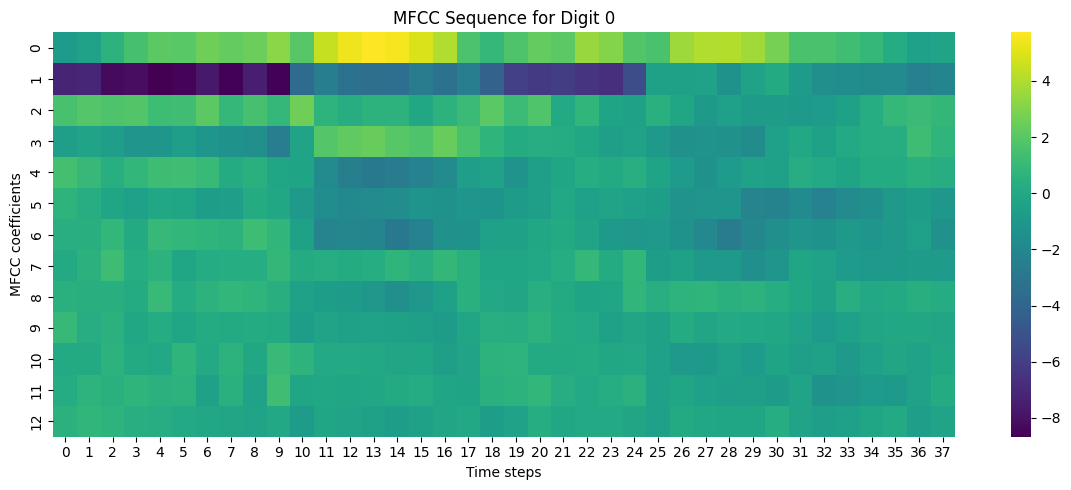

In [8]:
sample_index = 0

plt.figure(figsize=(12, 5))
sns.heatmap(train_sequences[sample_index].T, cmap="viridis")

plt.xlabel("Time steps")
plt.ylabel("MFCC coefficients")
plt.title(f"MFCC Sequence for Digit {train_labels[sample_index]}")
plt.tight_layout()
plt.show()

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    train_sequences,
    train_labels,
    test_size=0.15,
    random_state=42,
    stratify=train_labels
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(test_sequences))

Training: 5610
Validation: 990
Testing: 2200


In [10]:
class SpokenDigitDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = [
            torch.tensor(seq, dtype=torch.float32)
            for seq in sequences
        ]
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]


def collate_fn(batch):
    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [len(seq) for seq in sequences],
        dtype=torch.long
    )

    padded_sequences = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=0.0
    )

    return padded_sequences, lengths, torch.stack(labels)


BATCH_SIZE = 64

train_loader = DataLoader(
    SpokenDigitDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    SpokenDigitDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    SpokenDigitDataset(test_sequences, test_labels),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

x_batch, lengths_batch, y_batch = next(iter(train_loader))

print("Batch shape:", x_batch.shape)
print("Sequence lengths:", lengths_batch.shape)
print("Label shape:", y_batch.shape)

Batch shape: torch.Size([64, 61, 13])
Sequence lengths: torch.Size([64])
Label shape: torch.Size([64])


In [11]:
class SpokenDigitModel(nn.Module):
    def __init__(self, cell_type="RNN", hidden_size=64, num_layers=1):
        super().__init__()

        recurrent_cells = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }

        self.rnn = recurrent_cells[cell_type](
            input_size=13,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 10)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, state = self.rnn(packed)

        hidden = state[0] if isinstance(state, tuple) else state

        return self.fc(hidden[-1])

In [12]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for x, lengths, labels in loader:
        x = x.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(x, lengths)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)

        all_predictions.extend(
            outputs.argmax(dim=1).detach().cpu().numpy()
        )
        all_labels.extend(labels.detach().cpu().numpy())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_predictions)

    return average_loss, accuracy, all_labels, all_predictions

In [13]:
def train_model(
    cell_type="RNN",
    hidden_size=64,
    num_layers=1,
    learning_rate=0.001,
    threshold=1e-4,
    max_epochs=200
):
    model = SpokenDigitModel(
        cell_type=cell_type,
        hidden_size=hidden_size,
        num_layers=num_layers
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    previous_loss = None
    best_val_loss = float("inf")
    best_state = None

    for epoch in range(max_epochs):
        train_loss, train_acc, _, _ = run_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc, _, _ = run_epoch(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{cell_type} | Epoch {epoch + 1} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Train Accuracy: {train_acc:.4f} | "
            f"Validation Accuracy: {val_acc:.4f}"
        )

        if (
            previous_loss is not None
            and abs(train_loss - previous_loss) < threshold
        ):
            print("Convergence criterion reached.")
            break

        previous_loss = train_loss

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

In [14]:
results = {}

for cell_type in ["RNN", "LSTM", "GRU"]:
    model, history = train_model(
        cell_type=cell_type,
        hidden_size=64,
        num_layers=1
    )

    results[cell_type] = {
        "model": model,
        "history": history
    }

RNN | Epoch 1 | Train Loss: 1.88718 | Train Accuracy: 0.3242 | Validation Accuracy: 0.4081
RNN | Epoch 2 | Train Loss: 1.35344 | Train Accuracy: 0.5176 | Validation Accuracy: 0.5990
RNN | Epoch 3 | Train Loss: 1.06417 | Train Accuracy: 0.6059 | Validation Accuracy: 0.6566
RNN | Epoch 4 | Train Loss: 0.98289 | Train Accuracy: 0.6504 | Validation Accuracy: 0.5838
RNN | Epoch 5 | Train Loss: 1.13176 | Train Accuracy: 0.5948 | Validation Accuracy: 0.6697
RNN | Epoch 6 | Train Loss: 0.83639 | Train Accuracy: 0.6993 | Validation Accuracy: 0.7444
RNN | Epoch 7 | Train Loss: 0.72528 | Train Accuracy: 0.7535 | Validation Accuracy: 0.7657
RNN | Epoch 8 | Train Loss: 0.71531 | Train Accuracy: 0.7513 | Validation Accuracy: 0.7778
RNN | Epoch 9 | Train Loss: 0.69542 | Train Accuracy: 0.7556 | Validation Accuracy: 0.7616
RNN | Epoch 10 | Train Loss: 0.79897 | Train Accuracy: 0.7141 | Validation Accuracy: 0.7717
RNN | Epoch 11 | Train Loss: 0.71075 | Train Accuracy: 0.7537 | Validation Accuracy: 0.75

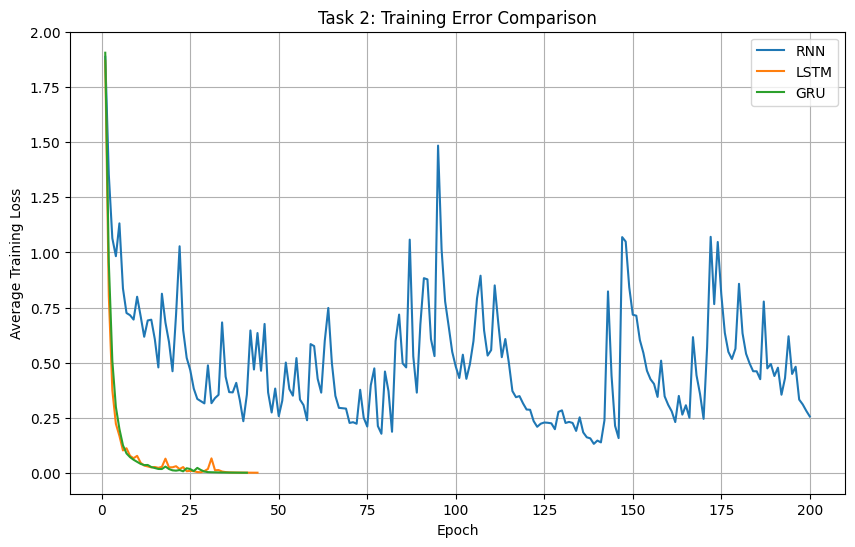

In [15]:
plt.figure(figsize=(10, 6))

for name, result in results.items():
    plt.plot(
        range(1, len(result["history"]["train_loss"]) + 1),
        result["history"]["train_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("Task 2: Training Error Comparison")
plt.legend()
plt.grid(True)
plt.show()


RNN Classification Report
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       220
           1       0.95      0.95      0.95       220
           2       0.90      0.93      0.92       220
           3       0.96      0.88      0.92       220
           4       0.99      0.97      0.98       220
           5       0.90      0.96      0.93       220
           6       0.95      0.79      0.86       220
           7       0.90      0.94      0.92       220
           8       0.90      0.90      0.90       220
           9       0.85      0.88      0.87       220

    accuracy                           0.90      2200
   macro avg       0.90      0.90      0.90      2200
weighted avg       0.90      0.90      0.90      2200



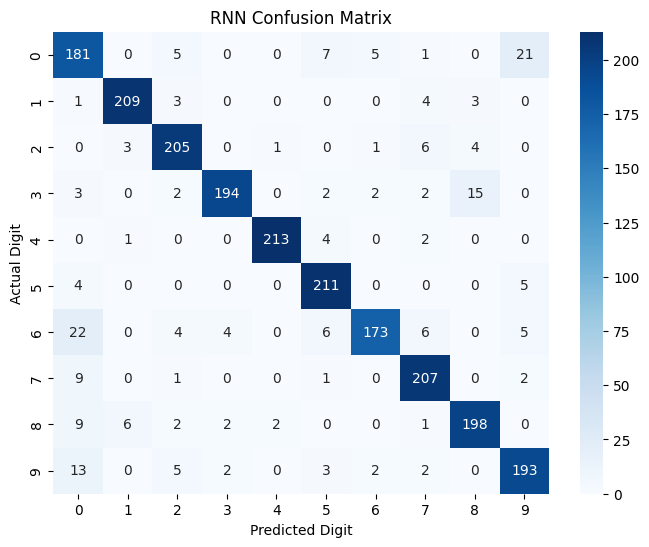


LSTM Classification Report
              precision    recall  f1-score   support

           0       0.89      0.95      0.92       220
           1       0.98      1.00      0.99       220
           2       0.98      0.97      0.98       220
           3       0.92      0.96      0.94       220
           4       0.98      1.00      0.99       220
           5       1.00      1.00      1.00       220
           6       0.98      0.89      0.93       220
           7       0.96      0.95      0.95       220
           8       0.99      0.96      0.97       220
           9       0.99      0.99      0.99       220

    accuracy                           0.97      2200
   macro avg       0.97      0.97      0.97      2200
weighted avg       0.97      0.97      0.97      2200



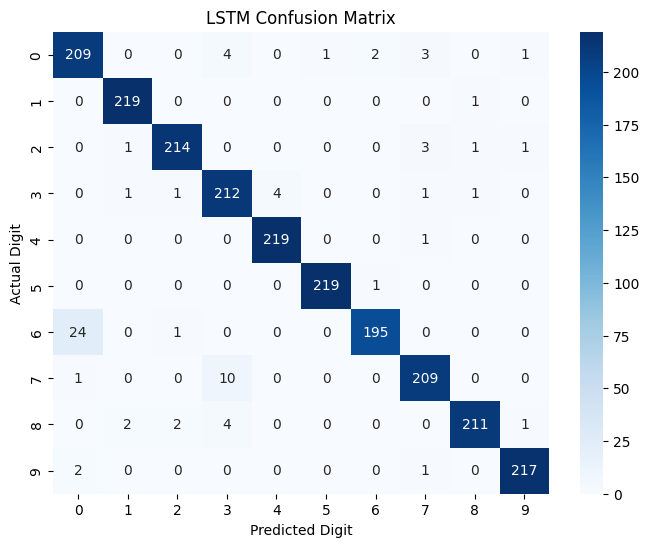


GRU Classification Report
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       220
           1       0.98      0.99      0.98       220
           2       0.96      0.97      0.96       220
           3       0.94      0.95      0.95       220
           4       0.99      0.97      0.98       220
           5       0.98      1.00      0.99       220
           6       1.00      0.91      0.95       220
           7       0.98      0.95      0.97       220
           8       0.97      0.97      0.97       220
           9       0.98      1.00      0.99       220

    accuracy                           0.97      2200
   macro avg       0.97      0.97      0.97      2200
weighted avg       0.97      0.97      0.97      2200



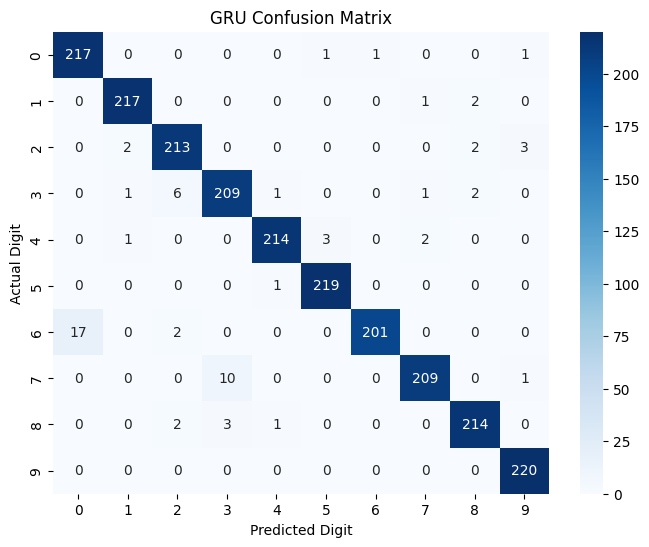

,Model,Training Accuracy,Test Accuracy,Test Loss
0,RNN,0.961497,0.901818,0.443034
1,LSTM,0.999822,0.965455,0.194288
2,GRU,1.000000,0.969545,0.145621


In [16]:
summary = []

for name, result in results.items():
    model = result["model"]
    criterion = nn.CrossEntropyLoss()

    test_loss, test_acc, y_true, y_pred = run_epoch(
        model, test_loader, criterion
    )

    train_loss, train_acc, _, _ = run_epoch(
        model, train_loader, criterion
    )

    summary.append({
        "Model": name,
        "Training Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Test Loss": test_loss
    })

    print(f"\n{name} Classification Report")
    print(classification_report(y_true, y_pred, labels=list(range(10))))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted Digit")
    plt.ylabel("Actual Digit")
    plt.title(f"{name} Confusion Matrix")
    plt.show()

results_df = pd.DataFrame(summary)
display(results_df)

In [17]:
for name, result in results.items():
    torch.save(
        result["model"].state_dict(),
        f"{name}_spoken_digit.pth"
    )

results_df.to_csv("task2_results.csv", index=False)

files.download("task2_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>